   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abbaye           NaN

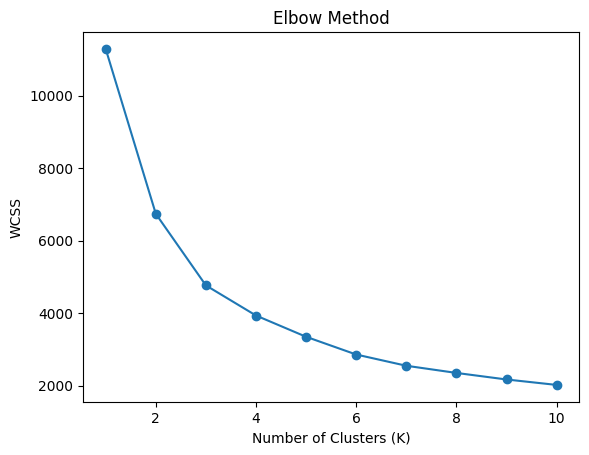


Cluster Count:
Cluster
2    996
0    975
1    852
Name: count, dtype: int64


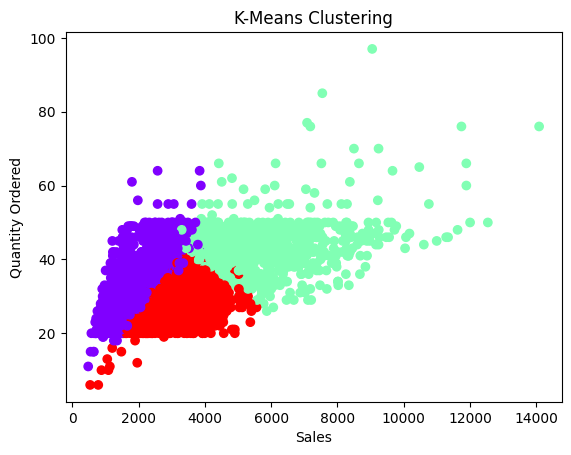

In [2]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 1. Read Dataset
df = pd.read_csv("/sales_data_sample.csv", encoding="latin1")
print(df.head())

# 2. Select Features
data = df[['QUANTITYORDERED', 'PRICEEACH', 'SALES', 'MSRP']]

# 3. Handle Missing Values
data = data.fillna(data.median())

# 4. Normalize Data
sc = StandardScaler()
X = sc.fit_transform(data)

# 5. Elbow Method
wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

# 6. Elbow Graph
plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

# 7. Apply K-Means (Example: 3 Clusters)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X)

print("\nCluster Count:")
print(df['Cluster'].value_counts())

# 8. Visualize Clusters
plt.scatter(data['SALES'], data['QUANTITYORDERED'],
            c=df['Cluster'], cmap='rainbow')

plt.xlabel("Sales")
plt.ylabel("Quantity Ordered")
plt.title("K-Means Clustering")
plt.show()
